# Organising the Dataset

Before we can start downloading and preprocessing medical imaging data we need to first clean and process the dataset, reducing it to only sessions that meet our requirements. The requirements being:

1. Simplify clinical diagnoses into binary labels.
2. Find the most common MRI type and select sessions
3. For each MRI find a corresponding PET session that is within 6 months
4. Apply labeled diagnosis with historical diagnoses data

## Reading the data

The Oasis 3 dataset supplies a folder with data about the MRI and PET scans, as well as the subjects and diagnosis. This data is fragmented into multiple csv files and an MRI scan does not necessarily have a corresponding PET scan. Some entries contain errors or null values that need to be dropped or replaced.

In [4]:
import os
import re
import pandas as pd
import numpy as np


dataset_path = "/home/kamran/projects/final-project/Datasets/Oasis-3"
data_path = "OASIS3_data_files/OASIS3_data_files/scans"
healthy = "OASIS_cohort_files/OASIS_cohort_files/scans/CogNorm-Cognitively_Normal_Cohorts/resources/csv/files/OASIS3_unchanged_CDR_cognitively_healthy.csv"
cdr = "UDSb4-Form_B4__Global_Staging__CDR__Standard_and_Supplemental/resources/csv/files/OASIS3_UDSb4_cdr.csv"
diag = "UDSd1-Form_D1__Clinician_Diagnosis___Cognitive_Status_and_Dementia/resources/csv/files/OASIS3_UDSd1_diagnoses.csv"
mri = "MRI-json-MRI_json_information/resources/csv/files/OASIS3_MR_json.csv"
pet = "PET-json-PET_json_information/resources/csv/files/OASIS3_PET_json.csv"
pup = "PUP-PUP_output/resources/csv/files/OASIS3_PUP.csv"

healthy_data = pd.read_csv(os.path.join(dataset_path, healthy))
cdr_data = pd.read_csv(os.path.join(dataset_path, data_path, cdr))
diag_data = pd.read_csv(os.path.join(dataset_path, data_path, diag))
mri_data = pd.read_csv(os.path.join(dataset_path, data_path, mri))
pet_data = pd.read_csv(os.path.join(dataset_path, data_path, pet))
pup_data = pd.read_csv(os.path.join(dataset_path, data_path, pup))

str_cols = ['OASISID', 'OASIS_session_label', 'dx1', 'dx2', 'dx3', 'dx4', 'dx5']
cdr_data[str_cols] = cdr_data[str_cols].apply(lambda s: s.astype(str))

# Find all cognitively healthy participants
healthy_ids = [str(x) for x in healthy_data['OASIS3_id'].unique()]
cdr_data_healthy = cdr_data[cdr_data['CDRTOT'] == 0]
cdr_healthy_ids = [str(x) for x in cdr_data_healthy.OASISID.unique()]

print("Received Healthy Diagnoses:",len(cdr_healthy_ids))
print("Unchanged Healthy:", len(healthy_ids))
difference = set(cdr_healthy_ids).difference(set(healthy_ids))
print("Converted:", len(difference))




Received Healthy Diagnoses: 1076
Unchanged Healthy: 755
Converted: 321


Dementia: 1231
Possible Dementia: 776
Normal: 6576
No Consensus: 0


<Axes: ylabel='count'>

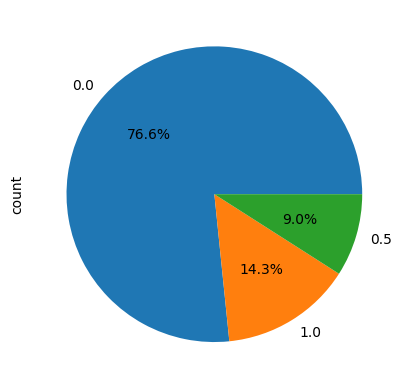

In [ ]:
# Find all records with dementia
dementia_data = cdr_data.copy()
dementia_data.replace({'.': None, np.nan: None}, inplace=True)

# Drop null records
dementia_data.dropna(subset=['dx1'], inplace=True)

def convert(d):
    """
    Classifies the diagnoses into 3 categories.
    
    1 = Dementia
    0.5 = Unclear
    0 = Non Dementia
    """
    keywords = ['DAT',
                'AD dem',
                'Vascular dem',
                'Frontotemporal dem',
                'Dementia', 'DLBD',
                'Incipient demt']
    if re.match(f'^({"|".join(keywords)})', d, re.I):
        return 1
    elif re.match('^uncertain*', d, re.I):
        return 0.5
    else:
        return 0

# Add new column
dementia_data['dementia'] = np.nan
dementia_data['confidence'] = np.nan

for index, row in dementia_data.iterrows():
    # If cdr is 0 or patient known healthy, continue
    if row['CDRTOT'] == 0 or row['OASISID'] in healthy_ids:
        dementia_data.at[index, 'dementia'] = 0
        continue

    assessment = convert(row['dx1'])

    # Iterate through supporting diagnosis
    # Is supporting diagnosis the same as initial
    # assessment?
    agree = 0
    disagree = 0
    for i in range(2, 6):
        d = row[f'dx{i}']
        if d == None:
            continue
        if d == 'A' or convert(row[f'dx{i}']) >= assessment:
            agree += 1
        else:
            disagree += 1
    
    # If more agree than disagree add label
    if agree >= disagree:
        dementia_data.at[index, 'dementia'] = assessment
    else:
        dementia_data.at[index, 'dementia'] = 0.5

print("Dementia:", dementia_data[dementia_data['dementia'] == 1].OASISID.count())
print("Possible Dementia:", dementia_data[dementia_data['dementia'] == 0.5].OASISID.count())
print("Normal:", dementia_data[dementia_data['dementia'] == 0].OASISID.count())
print("No Consensus:", dementia_data[dementia_data['dementia'].isnull()].OASISID.count())

# Drop all data where no consensus was reached (Saving for later analysis)
dementia_data[dementia_data['dementia'].isnull()].to_csv('no_consensus.csv')
dementia_data.dropna(subset=['dementia'], inplace=True, )

dementia_data['dementia'].value_counts().plot.pie(autopct='%1.1f%%')

/tmp/ipykernel_307688/2664870526.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .replace({True: 1, False: 0})


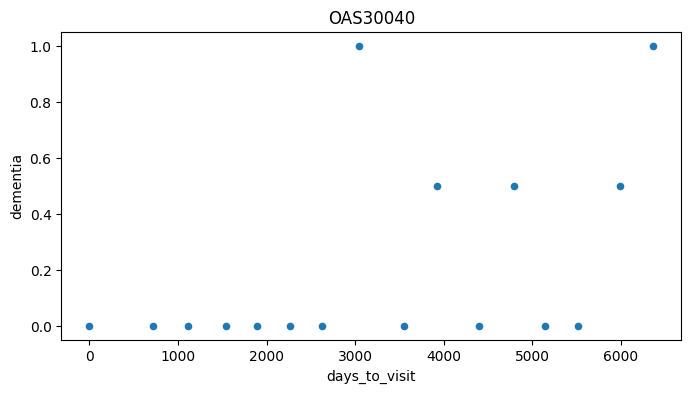

In [12]:
import matplotlib.pyplot as plt

subj = 'OAS30040'
(dementia_data.groupby('OASISID')
    .get_group(subj)
    .replace({True: 1, False: 0})
    .plot.scatter(x='days_to_visit', y='dementia', title=subj, figsize=(8,4)))
plt.show()